[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BrianAranda/Informes_FDPI/blob/tp3/code/ejercicio_4/ejercicio_4.ipynb)

# TP N.º 3 · Actividad 4: Filtros morfológicos para refinamiento de segmentación

**Objetivo.** Segmentar galaxias por umbralización y refinar la máscara con apertura y cierre, probando distintos tamaños y formas de elemento estructurante (EE), y evaluar la robustez del pipeline con imágenes de otros instrumentos.

- **Imagen principal:** Hubble eXtreme Deep Field (XDF, 2012, 872×1000 px), incluida en `scikit-image` (NASA, dominio público).
- **Robustez** (recortes de 1000×1000 px):
  - **Hubble Ultra Deep Field** (HUDF, 2004, cámara ACS): el mismo campo del cielo que el XDF, con menos exposición. NASA, ESA, S. Beckwith (STScI) y equipo HUDF, CC BY 4.0 (ESA/Hubble `heic0406a`).
  - **Primer campo profundo de Webb** (SMACS 0723, 2022, NIRCam): otro telescopio y otro procesamiento de color, con un cúmulo que agrega luz difusa al fondo. NASA, ESA, CSA, STScI, CC BY 4.0 (ESA/Webb `weic2209a`).

**Pipeline final:** canal $V$ (HSV) → umbral mediana $+3\sigma$ → apertura con disco $r=1$ → cierre con disco $r=1$.

Las figuras se guardan en `img/ejercicio_4/` y las imágenes descargadas en `datos/` (no se versiona).

In [1]:
# Entorno: en Colab clona el repositorio y se ubica en code/ejercicio_4. En local no hace nada.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    RAMA = "tp3"
    REPO = "https://github.com/BrianAranda/Informes_FDPI.git"
    DESTINO = "/content/Informes_FDPI"
    if not os.path.isdir(DESTINO):
        subprocess.run(["git", "clone", "--depth", "1", "--branch", RAMA, REPO, DESTINO], check=True)
    os.chdir(f"{DESTINO}/code/ejercicio_4")
    print("Trabajando en", os.getcwd())

## 1. Configuración e imágenes

In [2]:
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from skimage import data, color, filters, measure, morphology as mo, draw

Image.MAX_IMAGE_PIXELS = None
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "font.size": 11, "axes.titlesize": 11})
SALIDA = Path("../../img/ejercicio_4")      # figuras para el informe
SALIDA.mkdir(parents=True, exist_ok=True)
DATOS = Path("datos")                        # imágenes descargadas (no se versionan)
DATOS.mkdir(exist_ok=True)
pd.set_option("display.precision", 3)

def guardar(fig, nombre):
    fig.savefig(SALIDA / f"{nombre}.png")
    plt.show()

# Imágenes de robustez: se descargan solo la primera vez desde ESA/Hubble y ESA/Webb
FUENTES = {"hubble_ultra_deep_field_heic0406a.jpg": "https://cdn.esahubble.org/archives/images/large/heic0406a.jpg",
           "jwst_first_deep_field_weic2209a.jpg": "https://cdn.esawebb.org/archives/images/large/weic2209a.jpg"}
for nombre, url in FUENTES.items():
    if not (DATOS / nombre).exists():
        print("Descargando", nombre); urllib.request.urlretrieve(url, DATOS / nombre)

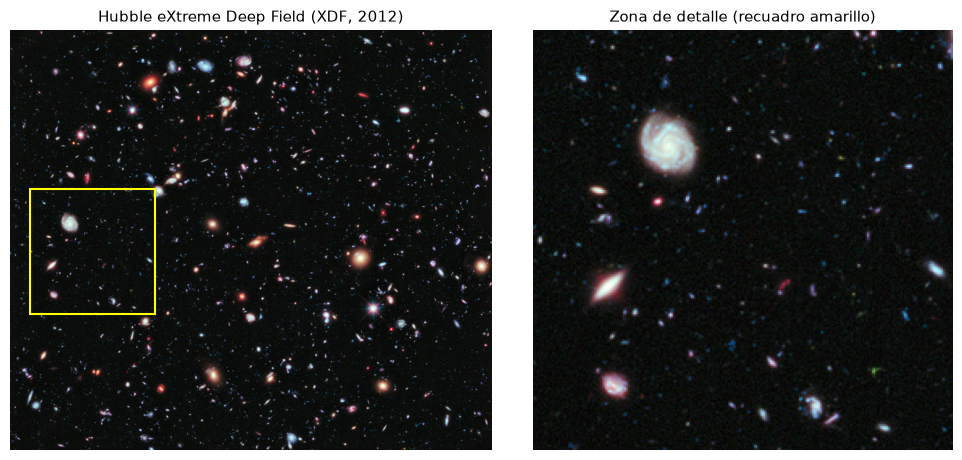

In [3]:
img = data.hubble_deep_field()          # XDF, RGB uint8
H, W, _ = img.shape
Z = (330, 40, 260, 260)                 # zona de detalle (fila, col, alto, ancho)
def recorte(a, z=Z):
    f, c, h, w = z
    return a[f:f + h, c:c + w]

fig, axs = plt.subplots(1, 2, figsize=(10, 4.6), gridspec_kw={"width_ratios": [1000 / 872, 1]})
axs[0].imshow(img); axs[0].set_title("Hubble eXtreme Deep Field (XDF, 2012)")
axs[0].add_patch(Rectangle((Z[1], Z[0]), Z[3], Z[2], fill=False, ec="yellow", lw=1.5))
axs[1].imshow(recorte(img)); axs[1].set_title("Zona de detalle (recuadro amarillo)")
for a in axs: a.axis("off")
plt.tight_layout()
guardar(fig, "original")

## 2. Segmentación

Las galaxias tienen colores muy distintos (rojas, azules, blancas): lo que las separa del fondo es el **brillo**, no el tono. $H$ y $S$ no sirven, porque en un píxel casi negro quedan dominados por el ruido de compresión. Se comparan $L^*$ (LAB) y $V$ (HSV, el máximo de R, G y B). El fondo se estima con la mediana y el ruido $\sigma$ con la MAD (desviación absoluta mediana × 1,4826), que no se dejan arrastrar por las galaxias.

Se comparan los dos canales con dos criterios: la SNR del pico de las galaxias brillantes según su color, y lo que detecta cada canal con el mismo criterio ($> \text{mediana} + 3\sigma$).

In [4]:
lab = color.rgb2lab(img)
V = color.rgb2hsv(img)[..., 2]
Lc = lab[..., 0] / 100

def fondo(c):
    med = np.median(c)
    return med, 1.4826 * np.median(np.abs(c - med))

med_V, s_V = fondo(V)
med_L, s_L = fondo(Lc)

# SNR del pico de las galaxias brillantes (pico > 10σ en V, área ≥ 30 px), por color
filas = []
for p in measure.regionprops(measure.label(V > med_V + 3 * s_V, connectivity=2)):
    if p.area < 30: continue
    rr, cc = p.coords[:, 0], p.coords[:, 1]
    snr_V = (V[rr, cc].max() - med_V) / s_V
    if snr_V < 10: continue
    a_m, b_m = lab[rr, cc, 1].mean(), lab[rr, cc, 2].mean()
    tipo = "roja" if a_m > 8 else ("azul" if b_m < -8 else "blanca")
    filas.append({"tipo": tipo, "SNR en V": snr_V, "SNR en L*": (Lc[rr, cc].max() - med_L) / s_L})
display(pd.DataFrame(filas).groupby("tipo").agg(n=("tipo", "size"), **{"SNR mediana en V": ("SNR en V", "median"),
                                                                       "SNR mediana en L*": ("SNR en L*", "median")}))

def deteccion(m):
    l = measure.label(m, connectivity=2); a = np.bincount(l.ravel())[1:]
    return {"primer plano %": 100 * m.mean(), "componentes": int(l.max()),
            "componentes ≥ 30 px": int((a >= 30).sum()), "componentes ≤ 4 px (ruido)": int((a <= 4).sum())}

t_otsu = filters.threshold_otsu(V)
t_3s = med_V + 3 * s_V
display(pd.DataFrame({"L* > mediana + 3σ": deteccion(Lc > med_L + 3 * s_L),
                      "V > mediana + 3σ": deteccion(V > t_3s),
                      f"V > Otsu ({t_otsu:.3f})": deteccion(V > t_otsu)}).T)
print(f"Fondo en V: mediana = {med_V:.4f}, σ = {s_V:.4f}  →  umbral mediana + 3σ = {t_3s:.3f}")

,n,SNR mediana en V,SNR mediana en L*
tipo,,,
azul,128,38.193,41.211
blanca,108,37.940,45.022
roja,156,40.217,45.717


,primer plano %,componentes,componentes ≥ 30 px,componentes ≤ 4 px (ruido)
L* > mediana + 3σ,10.465,6728.0,407.0,4448.0
V > mediana + 3σ,9.969,5379.0,392.0,3090.0
V > Otsu (0.346),4.190,2148.0,202.0,1228.0


Fondo en V: mediana = 0.0588, σ = 0.0233  →  umbral mediana + 3σ = 0.129


Ninguno de los dos canales penaliza a las galaxias de algún color. La diferencia está en el ruido: con el mismo criterio, $L^*$ detecta unos pocos objetos grandes más, pero muchas más motas. Se elige $V$.

El histograma de $V$ no es bimodal (más del 90 % de los píxeles son fondo): Otsu ubica el umbral muy alto y solo detecta los núcleos de las galaxias brillantes. Se usa el criterio habitual en astronomía, $V > \text{mediana} + 3\sigma$, que detecta también las galaxias tenues a cambio de dejar ruido que después limpia la morfología.

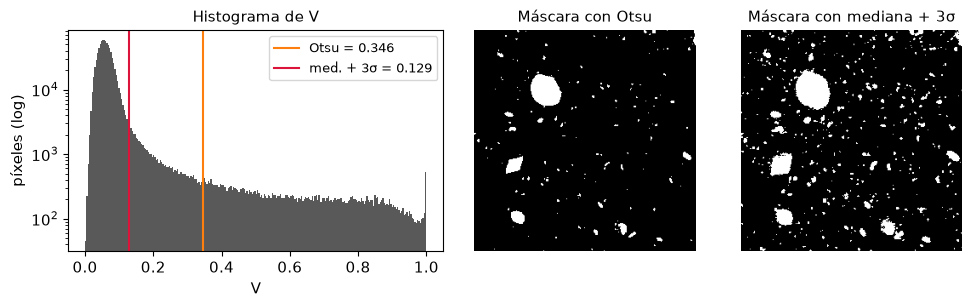

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3.2), gridspec_kw={"width_ratios": [1.5, 1, 1]})
axs[0].hist(V.ravel(), bins=256, color="0.35", log=True)
axs[0].axvline(t_otsu, color="tab:orange", lw=1.5, label=f"Otsu = {t_otsu:.3f}")
axs[0].axvline(t_3s, color="crimson", lw=1.5, label=f"med. + 3σ = {t_3s:.3f}")
axs[0].set_xlabel("V"); axs[0].set_ylabel("píxeles (log)"); axs[0].legend(fontsize=9); axs[0].set_title("Histograma de V")
for ax, t, k in [(axs[1], t_otsu, "Otsu"), (axs[2], t_3s, "mediana + 3σ")]:
    ax.imshow(recorte(V > t), cmap="gray"); ax.set_title(f"Máscara con {k}"); ax.axis("off")
plt.tight_layout()
guardar(fig, "umbral")

## 3. Máscara inicial y criterio de evaluación

La máscara inicial tiene miles de **motas de ruido**, huecos en las galaxias tenues, bordes irregulares y galaxias vecinas en contacto. Como no hay *ground truth*, se definen dos grupos de referencia con criterios que no dependen de la morfología:

- **Galaxias de referencia:** pico ≥ 10σ y área ≥ 30 px. Son objetos reales sin ambigüedad.
- **Motas de ruido:** pico < 5σ y área ≤ 10 px.
- Las componentes intermedias no se usan para evaluar.

Cada operación se evalúa con: **ruido eliminado** (motas de las que no queda ningún píxel), **galaxias conservadas** (galaxias cuyo píxel más brillante sigue en la máscara), **área de galaxias** conservada (erosión de bordes), **galaxias fusionadas** (galaxias que comparten componente con otra) y **huecos** (componentes del fondo que no tocan el borde).

Componentes: 5379  |  galaxias de referencia: 392  |  motas de ruido: 2108  |  sin clasificar: 2879
Motas: 1 a 8 px  |  galaxias de referencia: desde 30 px (mediana 62 px)


,ruido eliminado %,galaxias conservadas %,área de galaxias %,galaxias fusionadas,huecos,componentes
máscara inicial,0.0,100.0,100.0,0,134,5379


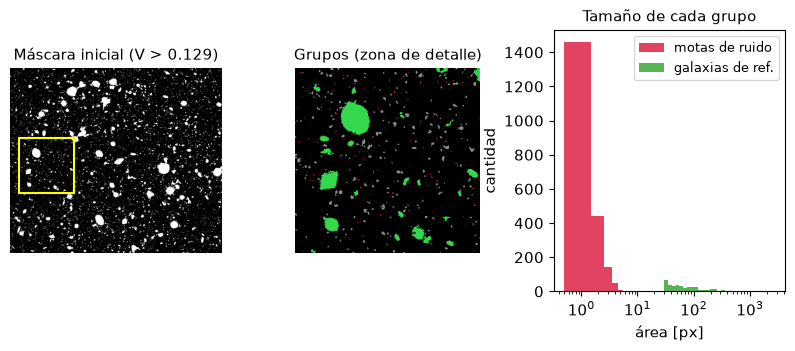

In [6]:
m0 = V > t_3s
lab0 = measure.label(m0, connectivity=2)
n0 = lab0.max()
pico = np.zeros(n0 + 1); np.maximum.at(pico, lab0.ravel(), V.ravel())
pico_snr = (pico - med_V) / s_V
area0 = np.bincount(lab0.ravel())

ref_ids = np.where((pico_snr >= 10) & (area0 >= 30))[0]; ref_ids = ref_ids[ref_ids > 0]
ruido_ids = np.where((pico_snr < 5) & (area0 <= 10))[0]; ruido_ids = ruido_ids[ruido_ids > 0]
pos_pico = {}
for p in measure.regionprops(lab0):
    if p.label in set(ref_ids):
        rr, cc = p.coords[:, 0], p.coords[:, 1]
        i = np.argmax(V[rr, cc]); pos_pico[p.label] = (rr[i], cc[i])
mask_ref = np.isin(lab0, ref_ids)
mask_ruido = np.isin(lab0, ruido_ids)

def contar_huecos(m):
    lb = measure.label(~m, connectivity=1)
    borde = np.unique(np.concatenate([lb[0], lb[-1], lb[:, 0], lb[:, -1]]))
    return int(len(np.setdiff1d(np.unique(lb), np.append(borde, 0))))

def metricas(m):
    l = measure.label(m, connectivity=2)
    vivas = np.zeros(n0 + 1, bool); vivas[np.unique(lab0[m & m0])] = True
    conserv = [i for i in ref_ids if m[pos_pico[i]]]
    _, cuenta = np.unique([l[pos_pico[i]] for i in conserv], return_counts=True)
    return {"ruido eliminado %": 100 * (1 - vivas[ruido_ids].mean()),
            "galaxias conservadas %": 100 * len(conserv) / len(ref_ids),
            "área de galaxias %": 100 * (m & mask_ref).sum() / mask_ref.sum(),
            "galaxias fusionadas": int(cuenta[cuenta > 1].sum()),
            "huecos": contar_huecos(m),
            "componentes": int(l.max())}

print(f"Componentes: {n0}  |  galaxias de referencia: {len(ref_ids)}  |  motas de ruido: {len(ruido_ids)}  |  "
      f"sin clasificar: {n0 - len(ref_ids) - len(ruido_ids)}")
print(f"Motas: {area0[ruido_ids].min()} a {area0[ruido_ids].max()} px  |  galaxias de referencia: desde {area0[ref_ids].min()} px "
      f"(mediana {np.median(area0[ref_ids]):.0f} px)")
display(pd.DataFrame([metricas(m0)], index=["máscara inicial"]))

clase = np.zeros(m0.shape + (3,))
clase[m0] = (0.55, 0.55, 0.55); clase[mask_ref] = (0.2, 0.85, 0.3); clase[mask_ruido] = (0.95, 0.2, 0.2)
fig = plt.figure(figsize=(10, 3.4))
gs = fig.add_gridspec(1, 3, width_ratios=[1000 / 872, 1, 1.25], wspace=0.35)
ax = fig.add_subplot(gs[0]); ax.imshow(m0, cmap="gray"); ax.set_title(f"Máscara inicial (V > {t_3s:.3f})"); ax.axis("off")
ax.add_patch(Rectangle((Z[1], Z[0]), Z[3], Z[2], fill=False, ec="yellow", lw=1.5))
ax = fig.add_subplot(gs[1]); ax.imshow(recorte(clase)); ax.axis("off"); ax.set_title("Grupos (zona de detalle)")
ax = fig.add_subplot(gs[2])
ax.hist(area0[ruido_ids], bins=np.arange(0.5, 12), color="crimson", alpha=.8, label="motas de ruido")
ax.hist(area0[ref_ids], bins=np.logspace(np.log10(30), np.log10(area0[ref_ids].max()), 30), color="tab:green", alpha=.8, label="galaxias de ref.")
ax.set_xscale("log"); ax.set_xlabel("área [px]"); ax.set_ylabel("cantidad"); ax.legend(fontsize=9); ax.set_title("Tamaño de cada grupo")
guardar(fig, "mascara_inicial")

## 4. Apertura y cierre

- **Apertura** $A \circ B = (A \ominus B) \oplus B$: elimina todo lo que no puede contener al EE.
- **Cierre** $A \bullet B = (A \oplus B) \ominus B$: rellena huecos y une objetos separados por menos que el EE.

Se prueban los EE pedidos (cuadrado 3×3 y 5×5, disco de radio 1 y 2, cruz 3×3 y 5×5). La cruz se construye a mano; el disco de radio 1 y la cruz 3×3 son el mismo EE. En la figura, en **rojo** lo que quita cada apertura.

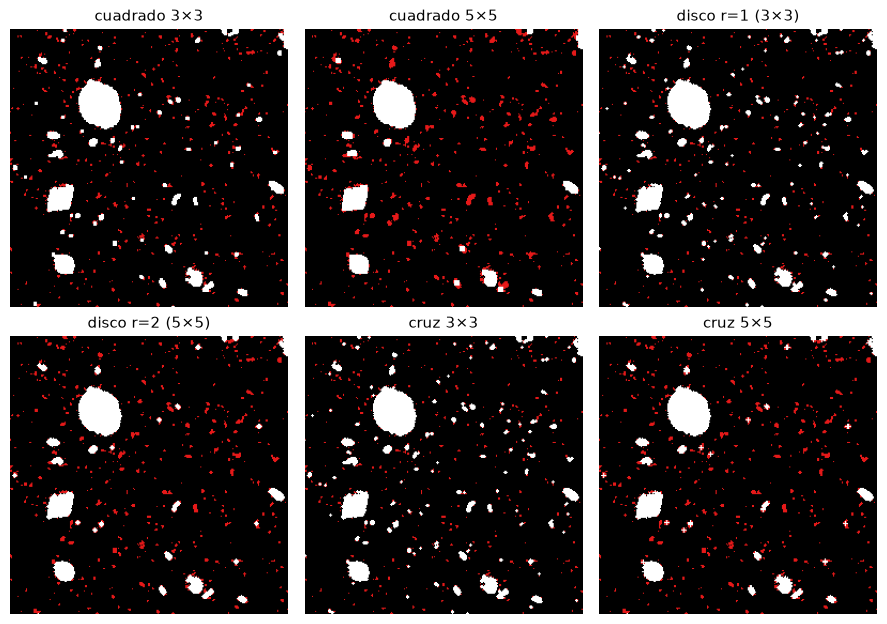

,apertura: ruido eliminado %,apertura: galaxias conservadas %,apertura: área de galaxias %,cierre: galaxias fusionadas,cierre: huecos
(inicial),0.000,100.000,100.000,0.0,134.0
cuadrado 3×3,100.000,97.959,92.289,47.0,10.0
cuadrado 5×5,100.000,65.561,78.323,93.0,5.0
disco r=1 (3×3),99.905,99.745,95.144,37.0,9.0
disco r=2 (5×5),100.000,93.112,87.572,59.0,8.0
cruz 3×3,99.905,99.745,95.144,37.0,9.0
cruz 5×5,100.000,91.837,87.560,47.0,6.0


In [7]:
def cuadrado(n): return np.ones((n, n), bool)
def disco(r):    return mo.disk(r).astype(bool)
def cruz(n):
    k = np.zeros((n, n), bool); k[n // 2, :] = True; k[:, n // 2] = True
    return k

EE = {"cuadrado 3×3": cuadrado(3), "cuadrado 5×5": cuadrado(5),
      "disco r=1 (3×3)": disco(1), "disco r=2 (5×5)": disco(2),
      "cruz 3×3": cruz(3), "cruz 5×5": cruz(5)}

def mapa_cambios(m, ref):
    out = np.zeros(m.shape + (3,))
    out[m & ref] = 1; out[ref & ~m] = (0.9, 0.1, 0.1); out[m & ~ref] = (0.1, 0.85, 0.2)
    return out

fig, axs = plt.subplots(2, 3, figsize=(9, 6.4))
filas = {"(inicial)": metricas(m0)}
for ax, (k, e) in zip(axs.flat, EE.items()):
    ap, ci = mo.opening(m0, e), mo.closing(m0, e)
    da, dc = metricas(ap), metricas(ci)
    filas[k] = {"apertura: ruido eliminado %": da["ruido eliminado %"],
                "apertura: galaxias conservadas %": da["galaxias conservadas %"],
                "apertura: área de galaxias %": da["área de galaxias %"],
                "cierre: galaxias fusionadas": dc["galaxias fusionadas"],
                "cierre: huecos": dc["huecos"]}
    ax.imshow(recorte(mapa_cambios(ap, m0))); ax.axis("off"); ax.set_title(k)
plt.tight_layout()
guardar(fig, "apertura")
d0 = filas.pop("(inicial)")
tabla = pd.DataFrame(filas).T
tabla.loc["(inicial)"] = [d0["ruido eliminado %"], d0["galaxias conservadas %"], d0["área de galaxias %"],
                          d0["galaxias fusionadas"], d0["huecos"]]
display(tabla.loc[["(inicial)"] + list(EE)])

Barrido del radio del disco de 1 a 6 en cada operación:

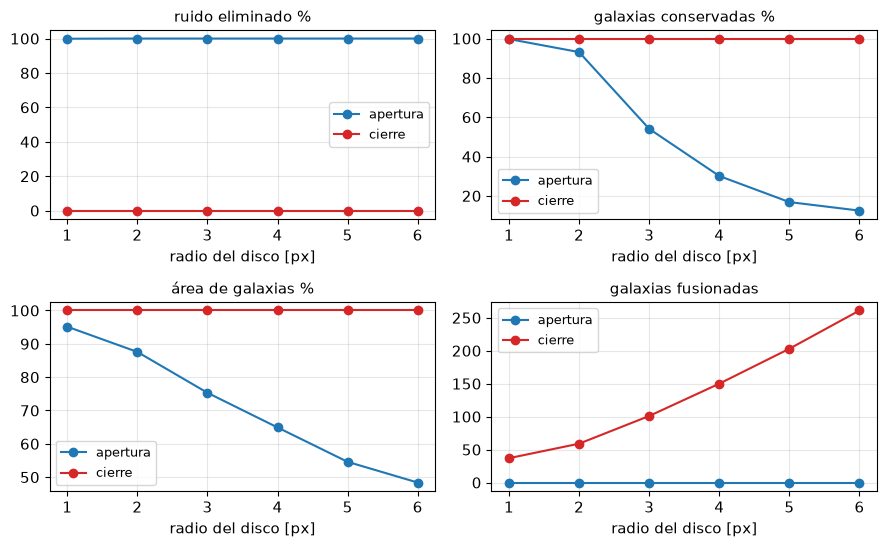

ruido eliminado %        galaxias conservadas %        área de galaxias %  \
op          apertura cierre               apertura cierre           apertura   
r                                                                              
1             99.905    0.0                 99.745  100.0             95.144   
2            100.000    0.0                 93.112  100.0             87.572   
3            100.000    0.0                 54.082  100.0             75.312   
4            100.000    0.0                 30.102  100.0             64.912   
5            100.000    0.0                 16.837  100.0             54.592   
6            100.000    0.0                 12.500  100.0             48.377   

          galaxias fusionadas         
op cierre            apertura cierre  
r                                     
1   100.0                 0.0   37.0  
2   100.0                 0.0   59.0  
3   100.0                 0.0  101.0  
4   100.0                 0.0  150.0  
5   100.0                 0.0  203.0  
6   100.0                 0.0  261.0

In [8]:
barr = []
for r in range(1, 7):
    for nombre, op in [("apertura", mo.opening), ("cierre", mo.closing)]:
        d = metricas(op(m0, disco(r))); d.update(op=nombre, r=r); barr.append(d)
barr = pd.DataFrame(barr)

cols = ["ruido eliminado %", "galaxias conservadas %", "área de galaxias %", "galaxias fusionadas"]
fig, axs = plt.subplots(2, 2, figsize=(9, 5.6))
for nombre, c in [("apertura", "tab:blue"), ("cierre", "tab:red")]:
    s = barr[barr.op == nombre]
    for ax, col in zip(axs.flat, cols): ax.plot(s.r, s[col], "o-", c=c, label=nombre)
for ax, col in zip(axs.flat, cols):
    ax.set_title(col); ax.set_xlabel("radio del disco [px]"); ax.grid(alpha=.3); ax.legend(fontsize=9)
plt.tight_layout()
guardar(fig, "barrido_tamanio")
display(barr.pivot(index="r", columns="op", values=cols))

## 5. Forma del elemento estructurante

A igual ventana (5×5: 25, 13 y 9 píxeles), el cuadrado es el más agresivo (en diagonal mide $\sqrt{2}$ veces más que de lado), el disco es isótropo y la cruz deja contornos dentados (ver la tabla de la sección 4).

Caso real donde la forma es decisiva: las estrellas de Webb tienen **picos de difracción** a 90°, 30° y 150°. Una apertura con **disco** los elimina (son finos) pero también se lleva las galaxias chicas; una apertura con **segmentos orientados** hace lo contrario: conserva los picos y elimina las galaxias compactas.

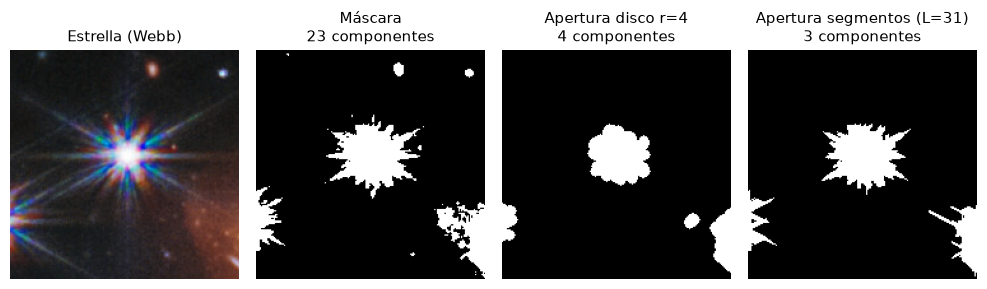

In [9]:
w_full = np.array(Image.open(DATOS / "jwst_first_deep_field_weic2209a.jpg"))
est = w_full[775:955, 3300:3480]                     # estrella con picos de difracción
Ve = color.rgb2hsv(est)[..., 2]
me, se = fondo(Ve)
m_est = Ve > me + 3 * se

def segmento(L, ang):
    k = np.zeros((L, L), bool); c = L // 2
    dx, dy = np.cos(np.deg2rad(ang)) * c, -np.sin(np.deg2rad(ang)) * c
    rr, cc = draw.line(int(round(c - dy)), int(round(c - dx)), int(round(c + dy)), int(round(c + dx)))
    k[rr, cc] = True
    return k

picos = np.zeros_like(m_est)
for ang in [90, 30, 150]:
    picos |= mo.opening(m_est, segmento(31, ang))

paneles = {"Estrella (Webb)": None, "Máscara": m_est,
           "Apertura disco r=4": mo.opening(m_est, disco(4)),
           "Apertura segmentos (L=31)": picos}
fig, axs = plt.subplots(1, 4, figsize=(10, 3.1))
for ax, (k, m) in zip(axs, paneles.items()):
    if m is None: ax.imshow(est)
    else:
        ax.imshow(m, cmap="gray")
        k += f"\n{measure.label(m, connectivity=2).max()} componentes"
    ax.set_title(k); ax.axis("off")
plt.tight_layout()
guardar(fig, "picos_difraccion")

## 6. Encadenado y máscara final

Con el radio útil de 1 se comparan los dos órdenes. Se elige **apertura → cierre**: elimina las motas mientras todavía están aisladas y después rellena. Al final se agrega un filtrado por área opcional (objetos de menos de 10 px).

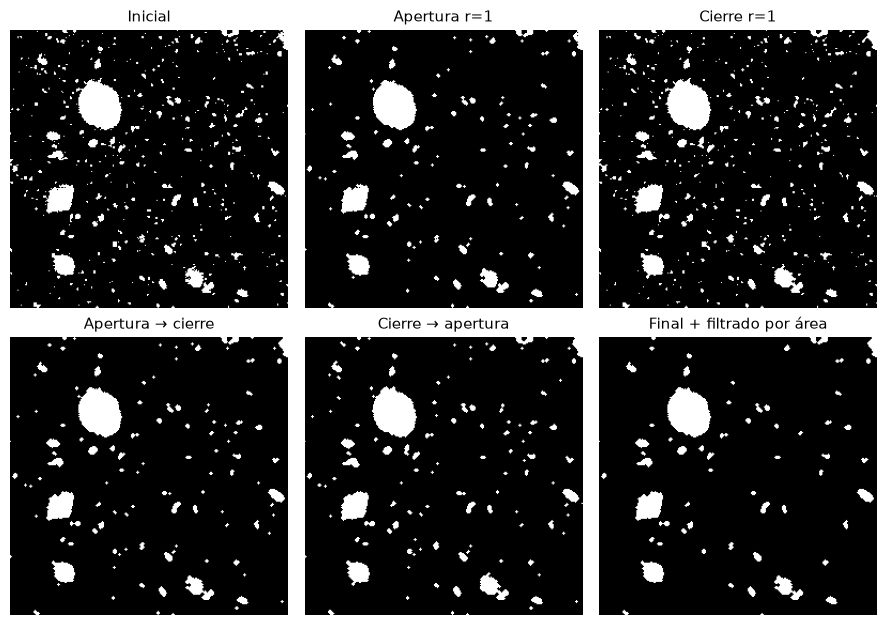

,ruido eliminado %,galaxias conservadas %,área de galaxias %,galaxias fusionadas,huecos,componentes
Inicial,0.000,100.000,100.000,0.0,134.0,5379.0
Apertura r=1,99.905,99.745,95.144,0.0,41.0,1678.0
Cierre r=1,0.000,100.000,100.000,37.0,9.0,4771.0
Apertura → cierre,99.905,99.745,95.221,8.0,1.0,1608.0
Cierre → apertura,97.154,99.745,97.603,30.0,3.0,1616.0
Final + filtrado por área,100.000,99.490,95.085,8.0,1.0,891.0


In [10]:
def filtrar_area(m, minimo=10):
    l = measure.label(m, connectivity=1)
    return m & (np.bincount(l.ravel())[l] >= minimo)

versiones = {
    "Inicial": m0,
    "Apertura r=1": mo.opening(m0, disco(1)),
    "Cierre r=1": mo.closing(m0, disco(1)),
    "Apertura → cierre": mo.closing(mo.opening(m0, disco(1)), disco(1)),
    "Cierre → apertura": mo.opening(mo.closing(m0, disco(1)), disco(1)),
}
final = versiones["Apertura → cierre"]
final_area = filtrar_area(final)
versiones["Final + filtrado por área"] = final_area

fig, axs = plt.subplots(2, 3, figsize=(9, 6.4))
for ax, (k, m) in zip(axs.flat, versiones.items()):
    ax.imshow(recorte(m), cmap="gray"); ax.set_title(k); ax.axis("off")
plt.tight_layout()
guardar(fig, "encadenado")
display(pd.DataFrame({k: metricas(m) for k, m in versiones.items()}).T)

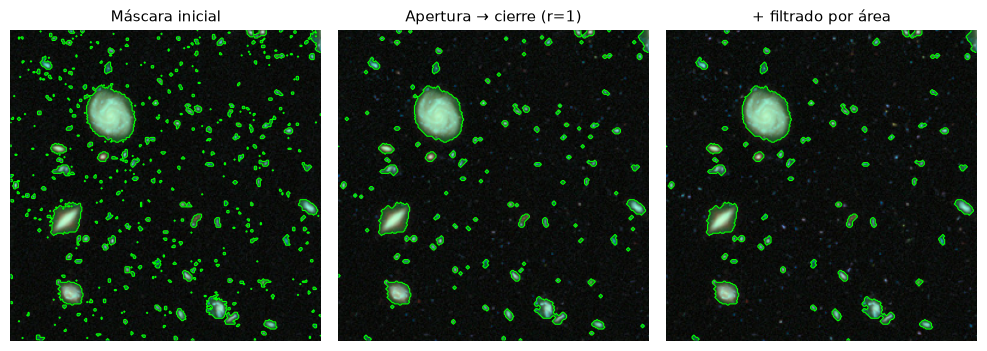

In [11]:
def superponer(ax, im, m, titulo, lw=0.8):
    ax.imshow(im)
    capa = np.zeros(m.shape + (4,)); capa[m] = (0.1, 0.9, 0.3, 0.25)
    ax.imshow(capa); ax.contour(m, [0.5], colors="lime", linewidths=lw)
    ax.set_title(titulo); ax.axis("off")

fig, axs = plt.subplots(1, 3, figsize=(10, 3.6))
superponer(axs[0], recorte(img), recorte(m0), "Máscara inicial")
superponer(axs[1], recorte(img), recorte(final), "Apertura → cierre (r=1)")
superponer(axs[2], recorte(img), recorte(final_area), "+ filtrado por área")
plt.tight_layout()
guardar(fig, "superposicion")

## 7. Robustez con otras imágenes

Se aplica la misma morfología a las tres imágenes con tres umbrales distintos:

- **A:** el umbral fijo calibrado en el XDF ($V > 0{,}129$).
- **B:** mediana $+3\sigma$ medidos en cada imagen.
- **C:** lo mismo que B, pero antes se resta el fondo con un **top-hat blanco** $V - (V \circ B)$ con un disco de radio 15: la apertura en grises con un disco grande estima el fondo, y al restarla quedan solo las estructuras más chicas que el disco.

,fondo,sigma
imagen,,
XDF 2012,0.059,0.023
HUDF 2004,0.114,0.070
Webb SMACS 0723,0.224,0.105


primer plano %  objetos  \
imagen          pipeline                                           
XDF 2012        A: umbral fijo                    8.117     1608   
                B: adaptativo                     8.117     1608   
                C: top-hat + adaptativo           7.275     1643   
HUDF 2004       A: umbral fijo                   13.711     6176   
                B: adaptativo                     2.583      137   
                C: top-hat + adaptativo           1.391      130   
Webb SMACS 0723 A: umbral fijo                   94.983      234   
                B: adaptativo                    10.559      103   
                C: top-hat + adaptativo           7.696      452   

                                         objetos ≥ 30 px  \
imagen          pipeline                                   
XDF 2012        A: umbral fijo                       362   
                B: adaptativo                        362   
                C: top-hat + adaptativo              369   
HUDF 2004       A: umbral fijo                       338   
                B: adaptativo                         68   
                C: top-hat + adaptativo               68   
Webb SMACS 0723 A: umbral fijo                        38   
                B: adaptativo                         42   
                C: top-hat + adaptativo              111   

                                         mayor componente % de la imagen  
imagen          pipeline                                                  
XDF 2012        A: umbral fijo                                     0.311  
                B: adaptativo                                      0.311  
                C: top-hat + adaptativo                            0.133  
HUDF 2004       A: umbral fijo                                     1.624  
                B: adaptativo                                      0.502  
                C: top-hat + adaptativo                            0.151  
Webb SMACS 0723 A: umbral fijo                                    94.489  
                B: adaptativo                                      3.956  
                C: top-hat + adaptativo                            1.217

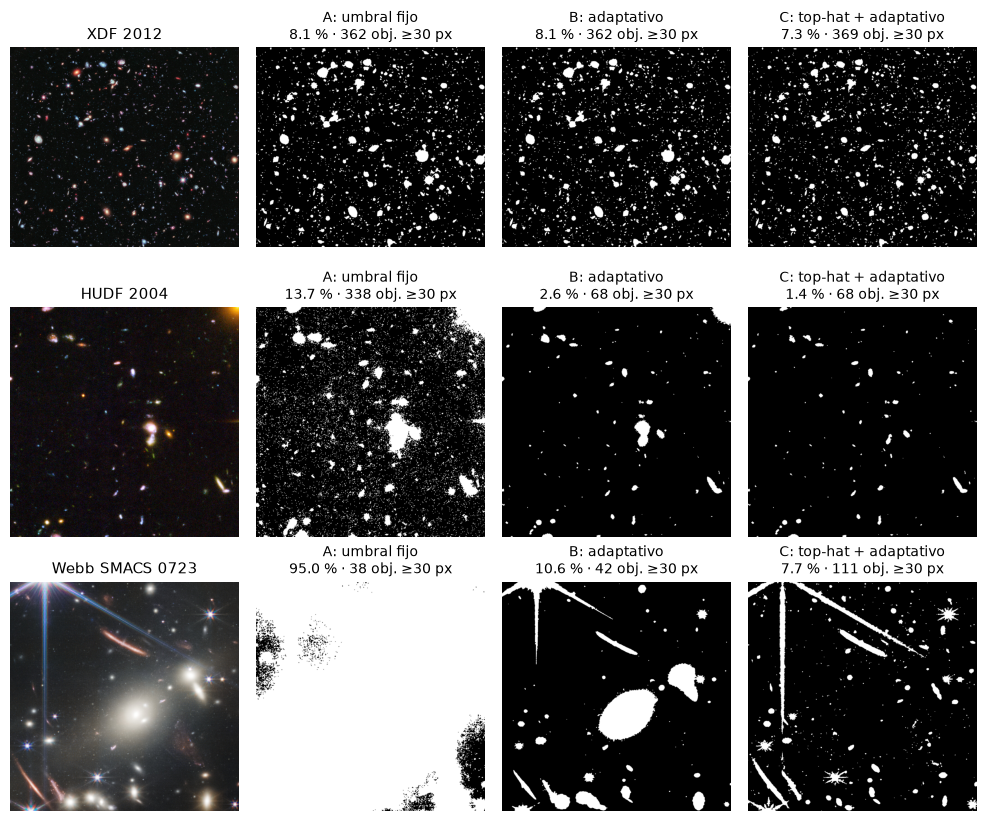

In [12]:
u_full = np.array(Image.open(DATOS / "hubble_ultra_deep_field_heic0406a.jpg"))
imagenes = {"XDF 2012": img,
            "HUDF 2004": u_full[2600:3600, 2600:3600],
            "Webb SMACS 0723": w_full[1800:2800, 1800:2800]}

def morfologia(m):
    return mo.closing(mo.opening(m, disco(1)), disco(1))

def descriptivas(m):
    l = measure.label(m, connectivity=2); a = np.bincount(l.ravel())[1:]
    return {"primer plano %": 100 * m.mean(), "objetos": int(l.max()), "objetos ≥ 30 px": int((a >= 30).sum()),
            "mayor componente % de la imagen": 100 * a.max() / m.size}

res, mascaras = [], {}
for k, im in imagenes.items():
    Vk = color.rgb2hsv(im)[..., 2]
    mk, sk = fondo(Vk)
    th = mo.white_tophat(Vk, mo.disk(15, decomposition="sequence"))
    mt, st = fondo(th)
    mascaras[k] = {"A: umbral fijo": morfologia(Vk > t_3s),
                   "B: adaptativo": morfologia(Vk > mk + 3 * sk),
                   "C: top-hat + adaptativo": morfologia(th > mt + 3 * st)}
    for p, m in mascaras[k].items():
        d = descriptivas(m); d.update(imagen=k, pipeline=p, fondo=mk, sigma=sk); res.append(d)
res = pd.DataFrame(res)
display(res.groupby("imagen", sort=False)[["fondo", "sigma"]].first())
display(res.set_index(["imagen", "pipeline"]).drop(columns=["fondo", "sigma"]))

fig, axs = plt.subplots(3, 4, figsize=(10, 8.4))
for i, (k, im) in enumerate(imagenes.items()):
    axs[i, 0].imshow(im); axs[i, 0].set_title(k); axs[i, 0].axis("off")
    for j, (p, m) in enumerate(mascaras[k].items()):
        d = descriptivas(m); ax = axs[i, j + 1]; ax.imshow(m, cmap="gray"); ax.axis("off")
        ax.set_title(f"{p}\n{d['primer plano %']:.1f} % · {d['objetos ≥ 30 px']} obj. ≥30 px", fontsize=10)
plt.tight_layout()
guardar(fig, "robustez")

## 8. Respuestas (resumen)

El desarrollo de cada respuesta está en el informe.

- **Apertura:** con disco r=1 elimina el 99,9 % del ruido externo y conserva el 99,7 % de las galaxias; pierde el 5 % de su área (bordes tenues). No distingue ruido de objeto, solo tamaño: con r=3 desaparece casi la mitad de las galaxias.
- **Cierre:** rellena los huecos (134 → 9), pero une objetos separados: 37 galaxias fusionadas con r=1 y 261 con r=6.
- **Tamaño del EE:** debe ser mayor que el ruido (1 a 8 px) y menor que el objeto más chico a detectar (~6 px de diámetro). El óptimo es r=1; la apertura define el tamaño mínimo detectable.
- **Forma del EE:** a igual ventana el cuadrado es mucho más agresivo y la cruz deja contornos dentados; el disco es el adecuado para objetos sin orientación. La forma es decisiva con estructuras de geometría conocida (picos de difracción, rayas, piezas rectangulares).
- **Robustez:** la morfología funciona mientras la escala de píxel sea parecida; el umbral fijo no. Hace falta umbral adaptativo, sustracción de fondo si no es uniforme, radios en unidades físicas y tratamiento de los artefactos de cada instrumento.
- **Orden:** hay que encadenarlas; con ruido externo dominante conviene apertura → cierre (el orden inverso casi cuadruplica las fusiones).
- **Inspección industrial:** es crítica: un píxel de radio cambia el conteo, y un EE mayor que el defecto mínimo lo borra.